In [24]:
import numpy as np
import matplotlib.pyplot as plt

Skin is represented in our paper as a homogenous, porous material. Thus, we will use Darcy's Law to represent the diffusion of insulin in the skin. 
Darcy flow law: $$Q = KA$$
which can be rewritten as:$$\vec V_D=-\frac{k_S}{\mu_i}\nabla p_S$$

First, solve for the following laplace equation to represent pressure inside skin:
$$\nabla^2p_S =\frac{\partial^2p_S}{\partial x^2} + \frac{\partial^2p_S}{\partial y^2}=0$$

We will use Gauss-Seidel to solve for pressure.

In [36]:
Ln = 1.5e-3 #m
skin_depth = 1.8e-3 #m
skin_width = 1.5e-3 #m
d_i = 200e-6 #m
dx = 10e-6 #m
dy = 10e-6 #m
Nx = int(skin_width/dx)
Ny = int((skin_depth - Ln)/dy)
x = np.linspace(-skin_width/2, skin_width/2, Nx + 1)
y = np.linspace(Ln, skin_depth, Ny + 1)
k = 6.2345e-14 #m^2
mu = 1.090e-3 #Pa*s
tol = 1e-6
u_in = [5.3e-6, 26.5e-6, 53.1e-6] #m/s
por = 0.638 #porosity

#----- Boundary Conditions -----
opening = np.abs(x) <= d_i / 2 + 1e-12                      # needle opening on top                           # bottom outflow nodes
capillary = (x >= 0.20e-3 - 1e-12) & (x <= 0.50e-3 + 1e-12)  #Neumann data on bottom edge: dp/dy = 0
# Neumann data on top edge: dp/dy = g_top (y points down into tissue)

In [27]:
def gauss_seidel(U_in, mu, k, dx, dy, Nx, Ny, tol, max_it=20000):
    g_top = np.where(opening, -U_in * mu / k, 0.0) #pressure at opening, will modify when I get needle data
    hist = []
    P = np.zeros((Nx + 1, Ny + 1))
    beta = dx / dy

    while k < max_it:
        Pold = P.copy()
        for l in range(1, Nx + 1):
            for j in range(0, Ny + 1):
                if j == Ny - 1 and not capillary[l]:
                    P[l, j] = 0.0
                    continue
                # x-neighbours; mirror across the side walls (dp/dx = 0)
                #left x cell
                Pw = P[l - 1, j] if l > 0 else P[l+1, j]
                #right x cell
                Pe = P[l + 1, j] if l < Nx else P[l-1, j]
                if j == 0:
                    Py = 2.0 * P[l, 1] - 2.0 * dy * g_top[l]    # prescribed flux / zero flux
                elif j == Ny:
                    Py = 2.0 * P[l, Ny - 1]                     # capillary: dp/dy = 0
                else:
                    Py = P[l, j - 1] + P[l, j + 1]

                P[l, j] = 0.25 * (Pw + Pe + Py)

        err = np.abs(P - Pold).max()
        hist.append(err)
        if err < tol:
            break
        k += 1
    return P, hist

In [28]:
results = {}
for U in u_in:
    P, hist = gauss_seidel(U, mu, k, dx, dy, int(Nx), int(Ny), tol)
    results[U] = (P, hist)
    print(f"U_in = {U*1e6:5.1f} um/s: {len(hist):5d} iterations, max p = {P.max():.2f} Pa")

U_in =   5.3 um/s:  7104 iterations, max p = 14.04 Pa
U_in =  26.5 um/s:  8456 iterations, max p = 70.20 Pa
U_in =  53.1 um/s:  9040 iterations, max p = 140.66 Pa


In [34]:
#----- Darcy velocity and mass-conservation check -----
def darcy_velocity(P, mu, k, dx, dy):
    dPdx, dPdy = np.gradient(P, dx, dy)      # P[i, j]: axis 0 = x, axis 1 = y
    return -(k / mu) * dPdx, -(k / mu) * dPdy
darcy_results = {}
for U in u_in:
    P,_ = results[U]
    u, v = darcy_velocity(P, mu, k, dx, dy) 
    darcy_results[U] = (u, v)
    q_in = U * d_i
    dPdy_bot = (3 * P[:, -1] - 4 * P[:, -2] + P[:, -3]) / (2 * dy)   # 2nd-order one-sided
    v_bot = np.where(~capillary, -(k / mu) * dPdy_bot, 0.0)
    q_out = np.trapezoid(v_bot, x)
    print(f"U_in = {U*1e6:5.1f} um/s: inflow {q_in:.3e}, outflow {q_out:.3e} m^2/s, "
          f"imbalance {abs(q_out - q_in)/q_in*100:.1f}%")

U_in =   5.3 um/s: inflow 1.060e-09, outflow -5.384e-10 m^2/s, imbalance 150.8%
U_in =  26.5 um/s: inflow 5.300e-09, outflow -2.692e-09 m^2/s, imbalance 150.8%
U_in =  53.1 um/s: inflow 1.062e-08, outflow -5.395e-09 m^2/s, imbalance 150.8%


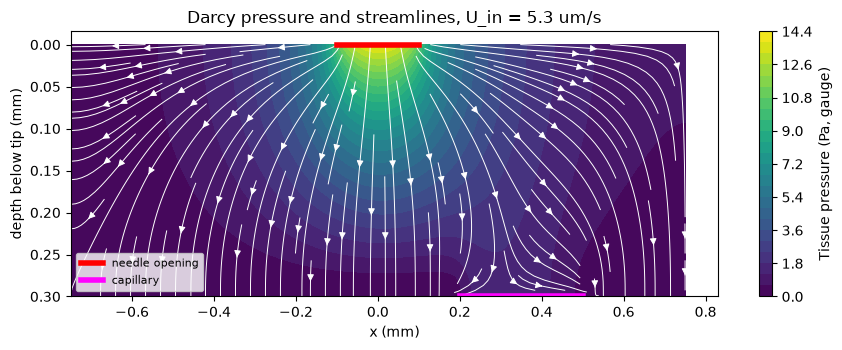

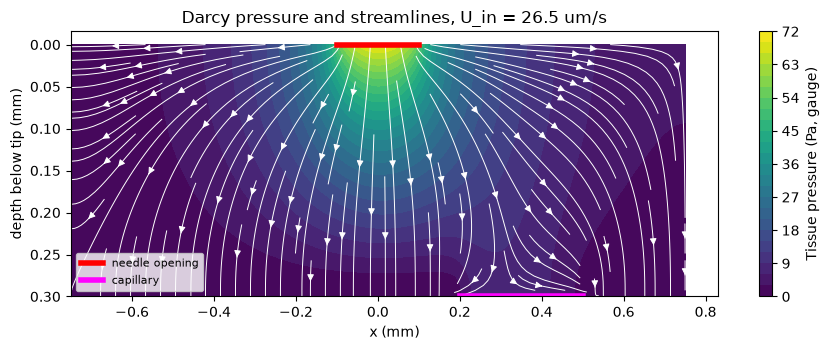

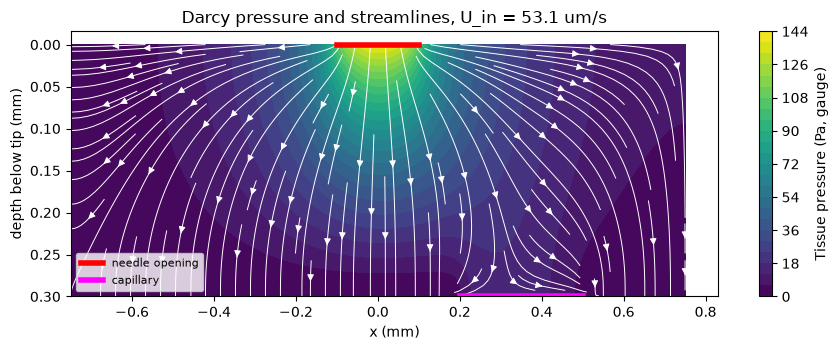

In [35]:
#----- Plot (first case) -----
U = u_in[0]
P, hist = results[U]
u, v = darcy_results[U]
X, Y = np.meshgrid(x * 1e3, (y - Ln) * 1e3, indexing="ij")   # y measured from the needle tip

fig, ax = plt.subplots(figsize=(9, 3.6))
cf = ax.contourf(X, Y, P, levels=25, cmap="viridis")
fig.colorbar(cf, label="Tissue pressure (Pa, gauge)")
ax.streamplot(x * 1e3, (y - Ln) * 1e3, u.T, v.T, color="white", density=1.4, linewidth=0.7)
ax.plot([-d_i / 2 * 1e3, d_i / 2 * 1e3], [0, 0], color="red", lw=4, label="needle opening")
ax.plot([0.20, 0.50], [(skin_depth - Ln) * 1e3] * 2, color="magenta", lw=4, label="capillary")
ax.invert_yaxis()
ax.set_xlabel("x (mm)"); ax.set_ylabel("depth below tip (mm)")
ax.set_title(f"Darcy pressure and streamlines, U_in = {U*1e6:.1f} um/s")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

#----- Plot (first case) -----
U = u_in[1]
P, hist = results[U]
u, v = darcy_results[U]
X, Y = np.meshgrid(x * 1e3, (y - Ln) * 1e3, indexing="ij")   # y measured from the needle tip

fig, ax = plt.subplots(figsize=(9, 3.6))
cf = ax.contourf(X, Y, P, levels=25, cmap="viridis")
fig.colorbar(cf, label="Tissue pressure (Pa, gauge)")
ax.streamplot(x * 1e3, (y - Ln) * 1e3, u.T, v.T, color="white", density=1.4, linewidth=0.7)
ax.plot([-d_i / 2 * 1e3, d_i / 2 * 1e3], [0, 0], color="red", lw=4, label="needle opening")
ax.plot([0.20, 0.50], [(skin_depth - Ln) * 1e3] * 2, color="magenta", lw=4, label="capillary")
ax.invert_yaxis()
ax.set_xlabel("x (mm)"); ax.set_ylabel("depth below tip (mm)")
ax.set_title(f"Darcy pressure and streamlines, U_in = {U*1e6:.1f} um/s")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

#----- Plot (first case) -----
U = u_in[2]
P, hist = results[U]
u, v = darcy_results[U]
X, Y = np.meshgrid(x * 1e3, (y - Ln) * 1e3, indexing="ij")   # y measured from the needle tip

fig, ax = plt.subplots(figsize=(9, 3.6))
cf = ax.contourf(X, Y, P, levels=25, cmap="viridis")
fig.colorbar(cf, label="Tissue pressure (Pa, gauge)")
ax.streamplot(x * 1e3, (y - Ln) * 1e3, u.T, v.T, color="white", density=1.4, linewidth=0.7)
ax.plot([-d_i / 2 * 1e3, d_i / 2 * 1e3], [0, 0], color="red", lw=4, label="needle opening")
ax.plot([0.20, 0.50], [(skin_depth - Ln) * 1e3] * 2, color="magenta", lw=4, label="capillary")
ax.invert_yaxis()
ax.set_xlabel("x (mm)"); ax.set_ylabel("depth below tip (mm)")
ax.set_title(f"Darcy pressure and streamlines, U_in = {U*1e6:.1f} um/s")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()
